In [28]:
!pip install -q "transformers<5" librosa soundfile

In [2]:
import librosa
import soundfile as sf
import transformers

print("Librosa:", librosa.__version__)
print("Soundfile:", sf.__version__)
print("Transformers:", transformers.__version__)

Librosa: 0.11.0
Soundfile: 0.14.0
Transformers: 4.57.6


In [3]:
from google.colab import files

uploaded = files.upload()

Saving fronbondi_skegs-field-howling-winds-outside-shaking-windows-field-recording-632808.mp3 to fronbondi_skegs-field-howling-winds-outside-shaking-windows-field-recording-632808.mp3


In [4]:
import librosa

audio_path = "fronbondi_skegs-field-howling-winds-outside-shaking-windows-field-recording-632808.mp3"

audio, sr = librosa.load(audio_path, sr=None)

print("Sample Rate:", sr)
print("Duration:", len(audio) / sr, "seconds")
print("Audio Shape:", audio.shape)

Sample Rate: 48000
Duration: 203.664 seconds
Audio Shape: (9775872,)


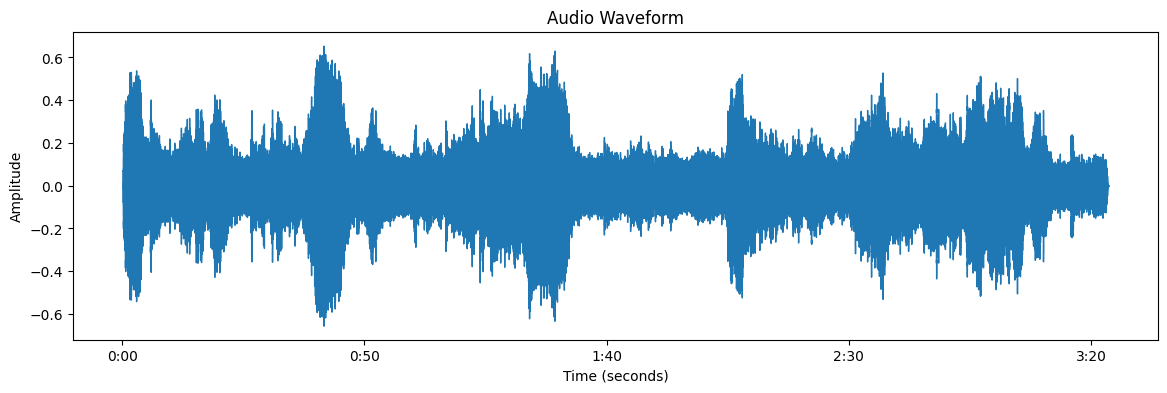

In [5]:
import matplotlib.pyplot as plt
import librosa.display

plt.figure(figsize=(14, 4))
librosa.display.waveshow(audio, sr=sr)
plt.title("Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

In [7]:
from transformers import pipeline

transcriber = pipeline(
    "automatic-speech-recognition",
    model="openai/whisper-base"
)

result = transcriber(audio_path, return_timestamps=True)

print(result["text"])

Device set to use cpu
Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.


 I'm going to have a look at how it's going to look like when I'm driving in the middle of the road. I'm going to have a look at how it's going to look like when I'm driving in the middle of the road. I'm going to have a look at how it's going to look like when I'm driving in the middle of the road. I'm going to have a look at how it's going to look like when I'm driving in the middle of the road. I'm going to have a look at how it's going to look like when I'm driving in the middle of the road. I'm going to have a look at how it's going to look like when I'm driving in the middle of the road. I'm going to have a look at how it's going to look like when I'm driving in the middle of the road. I'm going to have a look at how it's going to look like when I'm driving in the middle of the road. I'm going to have a look at how it's going to look like when I'm driving in the middle of the road. I'm going to have a look at how it's going to look like when I'm driving in the middle of the road.

In [8]:
from google.colab import files
uploaded = files.upload()

Saving freesound_community-speech-94649.mp3 to freesound_community-speech-94649.mp3


In [10]:
audio_path = "freesound_community-speech-94649.mp3"

result = transcriber(audio_path, return_timestamps=True)

print(result["text"])

 You are just a line of code.


In [11]:
print(result)

{'text': ' You are just a line of code.', 'chunks': [{'timestamp': (0.0, 2.0), 'text': ' You are just a line of code.'}]}


In [12]:
print(result["chunks"])

[{'timestamp': (0.0, 2.0), 'text': ' You are just a line of code.'}]


In [13]:
from transformers import pipeline

classifier = pipeline(
    "audio-classification",
    model="MIT/ast-finetuned-audioset-10-10-0.4593"
)

predictions = classifier(audio_path)

for p in predictions[:5]:
    print(p["label"], round(p["score"], 3))

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/297 [00:00<?, ?B/s]

Device set to use cpu
/usr/local/lib/python3.13/dist-packages/transformers/models/audio_spectrogram_transformer/feature_extraction_audio_spectrogram_transformer.py:118: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  waveform = torch.from_numpy(waveform).unsqueeze(0)


Speech 0.889
Speech synthesizer 0.039
Male speech, man speaking 0.022
Narration, monologue 0.01
Television 0.004


In [14]:
top = predictions[0]

print("Predicted Class:", top["label"])
print("Confidence:", round(top["score"] * 100, 2), "%")

Predicted Class: Speech
Confidence: 88.92 %


In [15]:
from transformers import pipeline

emotion_detector = pipeline(
    "audio-classification",
    model="ehcalabres/wav2vec2-lg-xlsr-en-speech-emotion-recognition"
)

emotion_results = emotion_detector(audio_path)

for result in emotion_results:
    print(result["label"], round(result["score"] * 100, 2), "%")

config.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/configuration_utils.py:335: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(


model.safetensors:   0%|          | 0.00/1.27G [00:00<?, ?B/s]

Some weights of the model checkpoint at ehcalabres/wav2vec2-lg-xlsr-en-speech-emotion-recognition were not used when initializing Wav2Vec2ForSequenceClassification: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.output.bias', 'classifier.output.weight']
- This IS expected if you are initializing Wav2Vec2ForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing Wav2Vec2ForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of Wav2Vec2ForSequenceClassification were not initialized from the model checkpoint at ehcalabres/wav2vec2-lg-xlsr-en-speech-emotion-recognition and are newly initialized: ['classifier.bias', 'classifier.weight', '

preprocessor_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

Device set to use cpu


neutral 13.78 %
sad 13.11 %
disgust 12.88 %
surprised 12.63 %
fearful 12.46 %
happy 12.06 %
calm 11.75 %
angry 11.34 %


In [16]:
print(emotion_detector.model.config.id2label)

{0: 'angry', 1: 'calm', 2: 'disgust', 3: 'fearful', 4: 'happy', 5: 'neutral', 6: 'sad', 7: 'surprised'}


In [17]:
print("Duration:", len(audio) / sr, "seconds")
print("Sample Rate:", sr)

Duration: 203.664 seconds
Sample Rate: 48000


In [20]:
!pip install -q silero-vad

In [21]:
import torch
from silero_vad import load_silero_vad, read_audio, get_speech_timestamps

print("Silero VAD imported successfully!")

Silero VAD imported successfully!


In [22]:
wind_path = "fronbondi_skegs-field-howling-winds-outside-shaking-windows-field-recording-632808.mp3"

wav = read_audio(wind_path)
speech_timestamps = get_speech_timestamps(
    wav,
    load_silero_vad(),
    return_seconds=True
)

print("Speech segments:", speech_timestamps)

/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Speech segments: []


In [23]:
speech_path = "freesound_community-speech-94649.mp3"

wav_speech = read_audio(speech_path)

speech_timestamps = get_speech_timestamps(
    wav_speech,
    load_silero_vad(),
    return_seconds=True
)

print("Speech segments:", speech_timestamps)

Speech segments: [{'start': 0.2, 'end': 1.7}]


In [24]:
start = int(0.2 * 16000)
end = int(1.7 * 16000)

speech_segment = wav_speech[start:end]

sf.write("speech_segment.wav", speech_segment, 16000)

print("Speech segment saved successfully!")

Speech segment saved successfully!


In [25]:
print("Extracted Duration:", len(speech_segment) / 16000, "seconds")
print("Extracted Shape:", speech_segment.shape)

Extracted Duration: 1.5 seconds
Extracted Shape: torch.Size([24000])


In [26]:
segment_result = transcriber("speech_segment.wav")

print("Extracted Speech:", segment_result["text"])

Extracted Speech:  You are just a line of code.


In [27]:
segment_predictions = classifier("speech_segment.wav")

for result in segment_predictions[:5]:
    print(result["label"], round(result["score"] * 100, 2), "%")

Speech 90.32 %
Speech synthesizer 1.89 %
Male speech, man speaking 1.86 %
Narration, monologue 0.85 %
Sound effect 0.46 %
